In [91]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

In [92]:
from scipy import stats
from scipy.stats.mstats import winsorize
from sklearn.compose import ColumnTransformer

## Step - 2 Data Import and Understanding

In [93]:
from google.colab import files
uploaded = files.upload()

Saving Customer Data.csv to Customer Data (2).csv


In [94]:
from google.colab import files
uploaded = files.upload()

Saving transactions.json to transactions (1).json


In [95]:
from google.colab import files
uploaded = files.upload()

Saving products.sql to products.sql


In [192]:
df = pd.read_csv("Customer Data.csv")
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


In [193]:
df1 = pd.read_json("transactions.json")
df1

,transaction_id,customer_id,product_id,amount,payment_mode,date
0,T001,101,P001,499,UPI,2025-10-01
1,T002,103,P003,1299,Credit Card,2025-10-02
2,T003,104,P002,699,Debit Card,2025-10-03
3,T004,105,P005,1999,UPI,2025-10-05
4,T005,107,P004,899,Cash,2025-10-07
5,T006,108,P006,2599,UPI,2025-10-08
6,T007,102,P003,1499,Credit Card,2025-10-09
7,T008,106,P001,499,Cash,2025-10-10


In [194]:
conn = sqlite3.connect("transactions.db")
conn

In [195]:
url = "https://dummyjson.com/users"
url

'https://dummyjson.com/users'

In [196]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  8 non-null      int64 
 1   name         8 non-null      object
 2   age          8 non-null      int64 
 3   gender       8 non-null      object
 4   city         8 non-null      object
 5   income       8 non-null      int64 
dtypes: int64(3), object(3)
memory usage: 516.0+ bytes


In [197]:
df.describe()

,customer_id,age,income
count,8.00000,8.000000,8.000000
mean,104.50000,30.000000,54125.000000
std,2.44949,5.903994,10494.045931
min,101.00000,22.000000,42000.000000
25%,102.75000,26.250000,47250.000000
50%,104.50000,29.500000,52500.000000
75%,106.25000,33.500000,58500.000000
max,108.00000,40.000000,75000.000000


In [198]:
df.head()

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000


# Step - 3 Exploratory Data Analysis (EDA)

Univariate Analysis

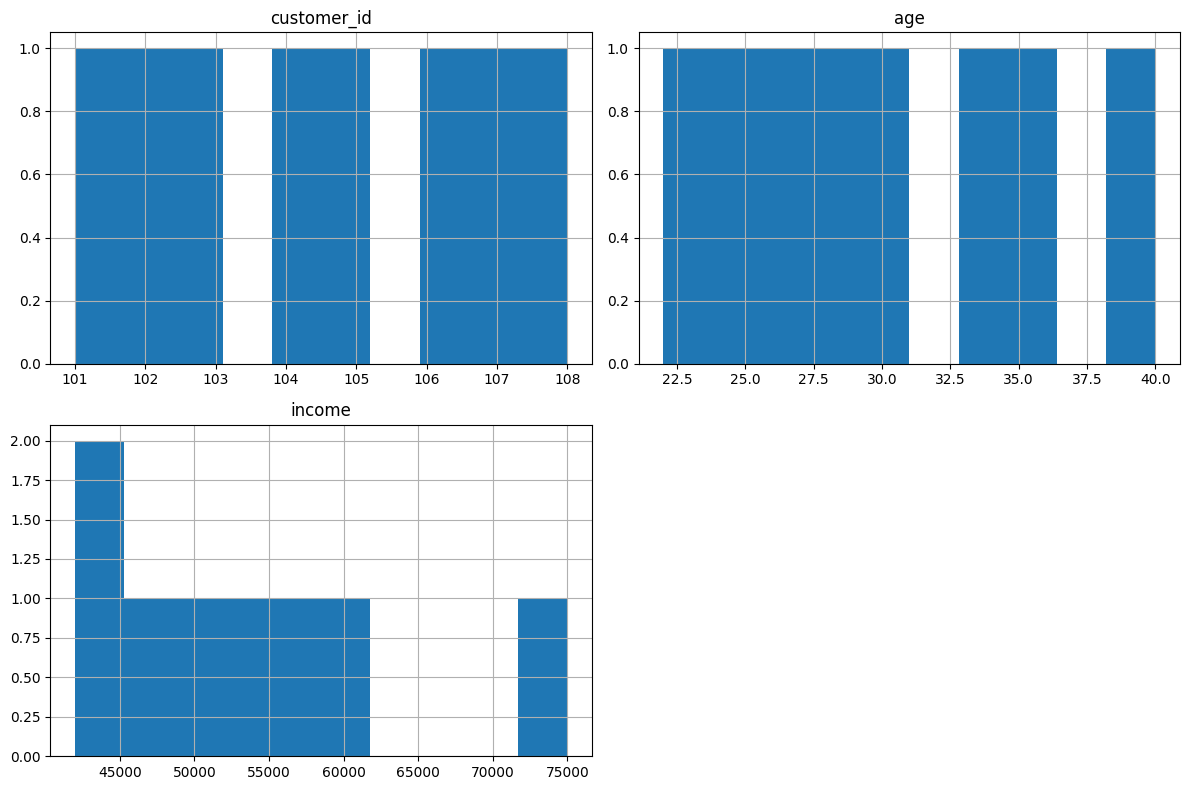

In [199]:
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

Skewness

In [200]:
print(df.select_dtypes(include="number").skew())

customer_id    0.000000
age            0.366520
income         1.073956
dtype: float64


Pandas Profiling

In [201]:
!pip install ydata-profiling

In [202]:
from ydata_profiling import ProfileReport

profile = ProfileReport(
    df,
    title="Customer Purchase Propensity - EDA Report",
    explorative=True,
)

profile.to_notebook_iframe()

profile.to_file("customer_data_profiling_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 6/6 [00:00<00:00, 54.48it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [203]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


# Bivariant

In [204]:
if "purchased" in df.columns:
    for col in ["income", "total_purchases", "age"]:
        if col in df.columns:
            plt.figure(figsize=(6, 3))
            sns.boxplot(x="purchased", y=col, data=df)
            plt.title(f"{col} vs Purchased")
            plt.show()

In [205]:
print(df.groupby("income").mean(numeric_only=True))

        customer_id   age
income                   
42000         106.0  22.0
45000         101.0  24.0
48000         103.0  27.0
50000         107.0  29.0
55000         102.0  30.0
58000         108.0  33.0
60000         104.0  35.0
75000         105.0  40.0


In [206]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


Multivariant

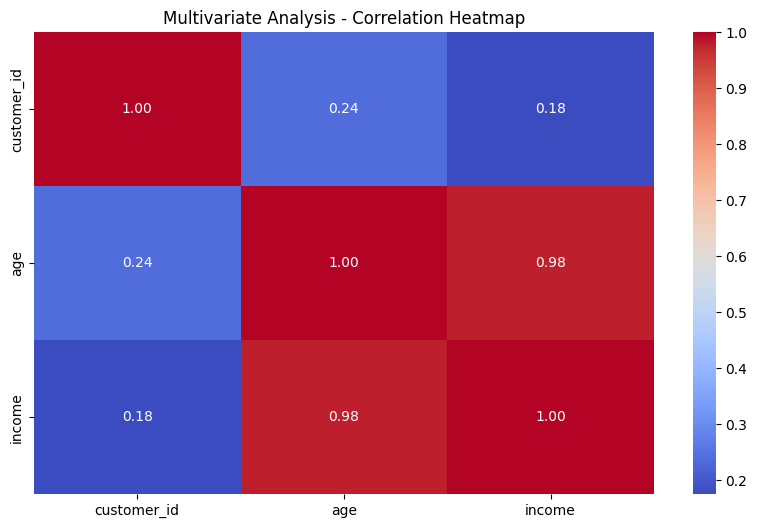

In [207]:
num_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(10, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Multivariate Analysis - Correlation Heatmap")
plt.show()

# Step - 4 Hadling Missing Data

Complete Case Analysis

In [208]:
df_cca = df.dropna()
print("Rows before CCA:", len(df), "| Rows after CCA:", len(df_cca))


Rows before CCA: 8 | Rows after CCA: 8


Simple Imputer

In [209]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

In [210]:
num_imputer

SimpleImputer(strategy='median')

In [186]:
cat_imputer

SimpleImputer(strategy='most_frequent')

Random Sample Imputer

In [187]:
from sklearn.impute import MissingIndicator

missing_ind = MissingIndicator()
if "income" in df.columns:
    df["income_nan_flag"] = missing_ind.fit_transform(df[["income"]])

    random_samples = df["income"].dropna().sample(df["income"].isnull().sum(), random_state=42)
    random_samples.index = df[df["income"].isnull()].index
    df["income_random_imputed"] = df["income"].copy()
    df.loc[df["income"].isnull(), "income_random_imputed"] = random_samples

In [189]:
missing_ind

MissingIndicator()

In [212]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


KNN Imputer

In [115]:
from sklearn.impute import KNNImputer

knn_imp = KNNImputer(n_neighbors=5)

In [116]:
knn_imp

KNNImputer()

MICE Algorithm

In [117]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

mice_imp = IterativeImputer(max_iter=10, random_state=42)
df[num_cols] = mice_imp.fit_transform(df[num_cols])

In [118]:
mice_imp

IterativeImputer(random_state=42)

# Step - 5 Outlier Detection & Handling

Z-Score Method

In [119]:
z_scores = np.abs(stats.zscore(df.select_dtypes(include=[np.number])))
outliers_z = (z_scores > 3).any(axis=1)
print("Outliers count (Z-score > 3):", outliers_z.sum())


Outliers count (Z-score > 3): 0


IQR Method

In [120]:
if "income" in df.columns:
    Q1 = df["income"].quantile(0.25)
    Q3 = df["income"].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    print(f"IQR Bounds for Income: [{lower_bound}, {upper_bound}]")


IQR Bounds for Income: [30375.0, 75375.0]


Percentile Method

In [121]:
lower_p = df["income"].quantile(0.01)
upper_p = df["income"].quantile(0.99)
df["income_capped"] = df["income"].clip(lower=lower_p, upper=upper_p)

In [122]:
upper_p

np.float64(73950.0)

In [123]:
lower_p

np.float64(42210.0)

Winsorization Method

In [124]:
df["income_winsorized"] = winsorize(df["income"], limits=[0.05, 0.05])

# Step - 6 Mixed & Date/ Time Variable

Date / Time Parsing

In [125]:
if "signup_date" in df.columns:
    df["signup_date"] = pd.to_datetime(df["signup_date"])
if "last_purchase_date" in df.columns:
    df["last_purchase_date"] = pd.to_datetime(df["last_purchase_date"])

    # Feature derivation
    current_reference_date = df["last_purchase_date"].max()
    df["days_since_last_purchase"] = (current_reference_date - df["last_purchase_date"]).dt.days

if "signup_date" in df.columns:
    df["days_since_signup"] = (pd.Timestamp.now() - df["signup_date"]).dt.days

In [214]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


Handling Mixed Variable

In [126]:
if "customer_id" in df.columns:
    df["customer_id_numeric"] = df["customer_id"].astype(str).str.extract("(\\d+)").astype(float)


In [215]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


# Step - 7 Encoding Category Data

Label Encoding

In [127]:
from sklearn.preprocessing import LabelEncoder

if "gender" in df.columns:
    le = LabelEncoder()
    df["gender_encoded"] = le.fit_transform(df["gender"].astype(str))

In [128]:
le

LabelEncoder()

In [216]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


One-Hot Encoding

In [129]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop="first")
if "category" in df.columns:
    cat_encoded = ohe.fit_transform(df[["category"]])
    cat_encoded_df = pd.DataFrame(cat_encoded, columns=ohe.get_feature_names_out(["category"]))
    df = pd.concat([df, cat_encoded_df], axis=1)

In [130]:
ohe

OneHotEncoder(drop='first', sparse_output=False)

In [217]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


ordinal Encoding

In [131]:
if "education" in df.columns:
    education_order = [["High School", "Bachelor", "Master", "PhD"]]
    ord_enc = OrdinalEncoder(categories=education_order)
    df["education_ord"] = ord_enc.fit_transform(df[["education"]])


In [218]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


Binning Feature

In [132]:
if "income" in df.columns:
    df["income_group"] = pd.qcut(df["income"], q=4, labels=["Low", "Medium", "High", "Very_High"])

In [219]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


# Step - 8 Feature Scaling

In [133]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler, Normalizer

std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
maxabs_scaler = MaxAbsScaler()
robust_scaler = RobustScaler()
normalizer = Normalizer()

In [134]:
scale_cols_std = ["age"] if "age" in df.columns else []
scale_cols_robust = ["income"] if "income" in df.columns else []

ct = ColumnTransformer(
    transformers=[
        ("std", StandardScaler(), scale_cols_std),
        ("robust", RobustScaler(), scale_cols_robust),
    ],
    remainder="passthrough",
)

In [135]:
std_scaler

StandardScaler()

In [220]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


In [136]:
minmax_scaler

MinMaxScaler()

In [137]:
maxabs_scaler

MaxAbsScaler()

In [138]:
robust_scaler

RobustScaler()

In [139]:
normalizer

Normalizer()

In [221]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


# Step - 9 Feature Construction & transformation

Interaction Feature

In [140]:
if "total_purchases" in df.columns and "days_since_signup" in df.columns:
    df["purchase_per_day"] = df["total_purchases"] / (df["days_since_signup"] + 1)


FunctionTransformer

In [141]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log1p, validate=True)
if "income" in df.columns:
    df["income_log"] = log_transformer.fit_transform(df[["income"]])

In [142]:
log_transformer

FunctionTransformer(func=<ufunc 'log1p'>, validate=True)

In [222]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


PowerTransformer

In [143]:
from sklearn.preprocessing import PowerTransformer

pt_yeo = PowerTransformer(method="yeo-johnson")
if "income" in df.columns:
    df["income_yeo"] = pt_yeo.fit_transform(df[["income"]])

In [144]:
pt_yeo

PowerTransformer()

In [223]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


Equal-width / Quantile Binning

In [145]:
from sklearn.preprocessing import KBinsDiscretizer

kbd = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile")
if "income" in df.columns:
    df["income_quantile_bin"] = kbd.fit_transform(df[["income"]])

In [146]:
kbd

KBinsDiscretizer(encode='ordinal', n_bins=4)

In [224]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


Binarization

# Step - 10 Final Output

In [225]:
df

,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000
5,106,Riya,22,Female,Chennai,42000
6,107,Aryan,29,Male,Kolkata,50000
7,108,Isha,33,Female,Surat,58000


In [226]:
output_filename = "processed_customer_data.csv"
df.to_csv(output_filename, index = False)